In [17]:
import osmnx as ox
import networkx as nx
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [18]:
ox.settings.use_cache = True

G = ox.graph_from_place(
    "Cambridge, Massachusetts, USA",
    network_type="walk"
)

print("Cambridge pedestrian network downloaded!")
print("Number of nodes:", len(G.nodes))
print("Number of edges:", len(G.edges))

Cambridge pedestrian network downloaded!
Number of nodes: 12259
Number of edges: 33412


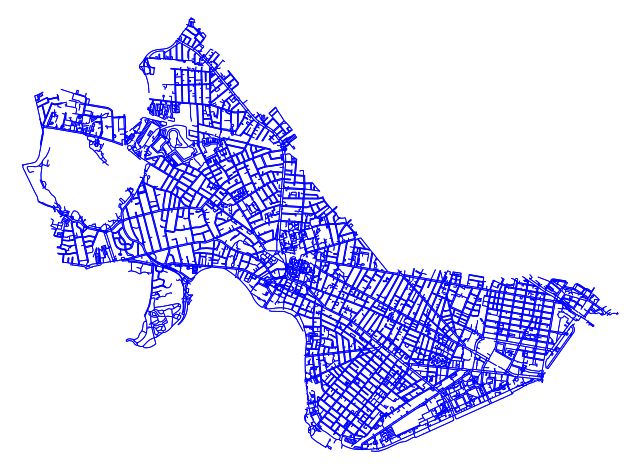

In [19]:
fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_color="blue",
    edge_linewidth=0.6,
    bgcolor="white"
)

plt.show()

In [20]:
ox.save_graphml(
    G,
    filepath="cambridge_walking_network.graphml"
)

print("Network saved successfully!")

Network saved successfully!


In [21]:
print(type(G))
print("Nodes:", len(G.nodes))
print("Edges:", len(G.edges))


<class 'networkx.classes.multidigraph.MultiDiGraph'>
Nodes: 12259
Edges: 33412


In [22]:
G = ox.load_graphml("cambridge_walking_network.graphml")

In [23]:
nodes_gdf, edges_gdf = ox.graph_to_gdfs(
    G,
    nodes=True,
    edges=True
)

print("Nodes dataset:")
print(nodes_gdf.head())

print("Edges dataset:")
print(edges_gdf.head())

Nodes dataset:
                  y          x  street_count          highway  ref railway  \
osmid                                                                        
61171565  42.374222 -71.093731             1              NaN  NaN     NaN   
61283273  42.356868 -71.113558             1              NaN  NaN     NaN   
61283403  42.371404 -71.133535             1              NaN  NaN     NaN   
61316733  42.371097 -71.134563             6              NaN  NaN     NaN   
61316736  42.374707 -71.130585             1  traffic_signals  NaN     NaN   

                            geometry  
osmid                                 
61171565  POINT (-71.09373 42.37422)  
61283273  POINT (-71.11356 42.35687)  
61283403   POINT (-71.13354 42.3714)  
61316733   POINT (-71.13456 42.3711)  
61316736  POINT (-71.13058 42.37471)  
Edges dataset:
                               osmid       access    highway        service  \
u        v           key                                               

In [24]:
print("Node columns:")
print(nodes_gdf.columns.tolist())

print("\nEdge columns:")
print(edges_gdf.columns.tolist())

Node columns:
['y', 'x', 'street_count', 'highway', 'ref', 'railway', 'geometry']

Edge columns:
['osmid', 'access', 'highway', 'service', 'oneway', 'reversed', 'length', 'lanes', 'name', 'width', 'geometry', 'maxspeed', 'tunnel', 'ref', 'bridge', 'junction']


In [25]:
number_of_nodes = len(nodes_gdf)
number_of_edges = len(edges_gdf)

print("Total nodes:", number_of_nodes)
print("Total directed edges:", number_of_edges)

Total nodes: 12259
Total directed edges: 33412


In [26]:
G_projected = ox.project_graph(G)

G_undirected = ox.convert.to_undirected(G_projected)

physical_edges = ox.graph_to_gdfs(
    G_undirected,
    nodes=False,
    edges=True
)

total_length_m = physical_edges["length"].sum()

print("Total pedestrian network length:")
print(round(total_length_m / 1000, 2), "km")

Total pedestrian network length:
608.5 km


In [27]:
longest_segments = physical_edges.nlargest(
    10,
    "length"
)

print(longest_segments[["length"]])

                                 length
u           v           key            
1093023632  1093023579  0    689.721694
346042522   1093023767  0    565.678235
5235225256  3616266417  0    539.709869
7632574078  7632574171  0    482.570815
61324708    346032624   0    477.750833
7629151264  7629193491  0    477.550825
7629085116  7629085127  0    477.440709
12945304418 7579230366  0    476.793020
61321463    12377498809 0    475.148882
346034325   346034891   0    451.874260


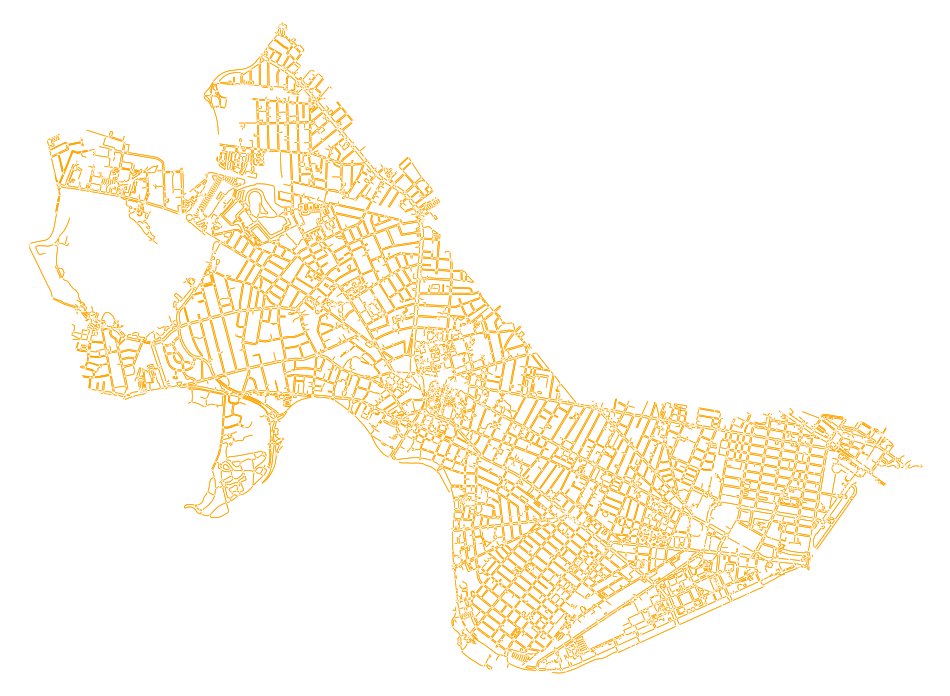

In [28]:
fig, ax = ox.plot_graph(
    G,
    node_size=1,
    edge_color="orange",
    edge_linewidth=0.5,
    bgcolor="white",
    figsize=(12, 12)
)

plt.show()

In [29]:
nodes_projected, edges_projected = ox.graph_to_gdfs(
    G_projected,
    nodes=True,
    edges=True
)

nodes_projected.to_file(
    "cambridge_pedestrian_network.gpkg",
    layer="nodes",
    driver="GPKG"
)

edges_projected.to_file(
    "cambridge_pedestrian_network.gpkg",
    layer="edges",
    driver="GPKG"
)

print("Both GIS datasets saved successfully!")

Both GIS datasets saved successfully!


In [30]:
import osmnx as ox
import pandas as pd

In [31]:
places = [
    "Harvard University, Cambridge, Massachusetts, USA",
    "Massachusetts Institute of Technology, Cambridge, Massachusetts, USA",
    "Kendall Square, Cambridge, Massachusetts, USA",
    "Central Square, Cambridge, Massachusetts, USA",
    "Cambridge Public Library, Cambridge, Massachusetts, USA"
]

results = []

for place in places:
    try:
        lat, lon = ox.geocode(place)

        results.append({
            "Destination": place,
            "Latitude": lat,
            "Longitude": lon
        })

        print("Collected:", place)

    except Exception as e:
        print("Could not find:", place, e)

destinations = pd.DataFrame(results)

destinations

Collected: Harvard University, Cambridge, Massachusetts, USA
Collected: Massachusetts Institute of Technology, Cambridge, Massachusetts, USA
Collected: Kendall Square, Cambridge, Massachusetts, USA
Collected: Central Square, Cambridge, Massachusetts, USA
Collected: Cambridge Public Library, Cambridge, Massachusetts, USA


,Destination,Latitude,Longitude
0,"Harvard University, Cambridge, Massachusetts, USA",42.365743,-71.122214
1,"Massachusetts Institute of Technology, Cambrid...",42.358253,-71.096627
2,"Kendall Square, Cambridge, Massachusetts, USA",42.362611,-71.087610
3,"Central Square, Cambridge, Massachusetts, USA",42.365509,-71.104001
4,"Cambridge Public Library, Cambridge, Massachus...",42.373987,-71.110470


In [32]:
print(destinations)

                                         Destination   Latitude  Longitude
0  Harvard University, Cambridge, Massachusetts, USA  42.365743 -71.122214
1  Massachusetts Institute of Technology, Cambrid...  42.358253 -71.096627
2      Kendall Square, Cambridge, Massachusetts, USA  42.362611 -71.087610
3      Central Square, Cambridge, Massachusetts, USA  42.365509 -71.104001
4  Cambridge Public Library, Cambridge, Massachus...  42.373987 -71.110470


In [33]:
destinations.to_csv("cambridge_destinations.csv", index=False)

print("File saved successfully!")

File saved successfully!


In [34]:
import os

print(os.getcwd())

E:\Jupyter Notebook


In [35]:
import osmnx as ox
import networkx as nx
import pandas as pd
import numpy as np

G = ox.load_graphml("cambridge_walking_network.graphml")

print("Network loaded:", len(G.nodes), "nodes")

Network loaded: 12259 nodes


In [36]:
import random

random.seed(42)

nodes = list(G.nodes)

routes = []

while len(routes) < 100:

    origin, destination = random.sample(nodes, 2)

    try:
        distance = nx.shortest_path_length(
            G,
            source=origin,
            target=destination,
            weight="length"
        )

        routes.append({
            "Origin": origin,
            "Destination": destination,
            "Distance_m": distance
        })

    except nx.NetworkXNoPath:
        continue

routes_df = pd.DataFrame(routes)

routes_df.head(10)

,Origin,Destination,Distance_m
0,11964365785,2292063720,7832.428931
1,61326403,13969192297,3200.750787
2,7629511703,7628787258,5706.073097
3,7626171388,4330581211,1804.714343
4,13859562651,1706528830,5652.255404
5,12425627973,13958249111,3558.925626
6,8691810324,1102965403,1896.301421
7,10118780648,7890165295,5175.407812
8,61330561,61329665,2419.079456
9,1412454631,7625819647,2420.836056


In [37]:
routes_df.to_csv(
    "cambridge_walking_routes.csv",
    index=False
)

NameError: name 'locations_gdf' is not defined

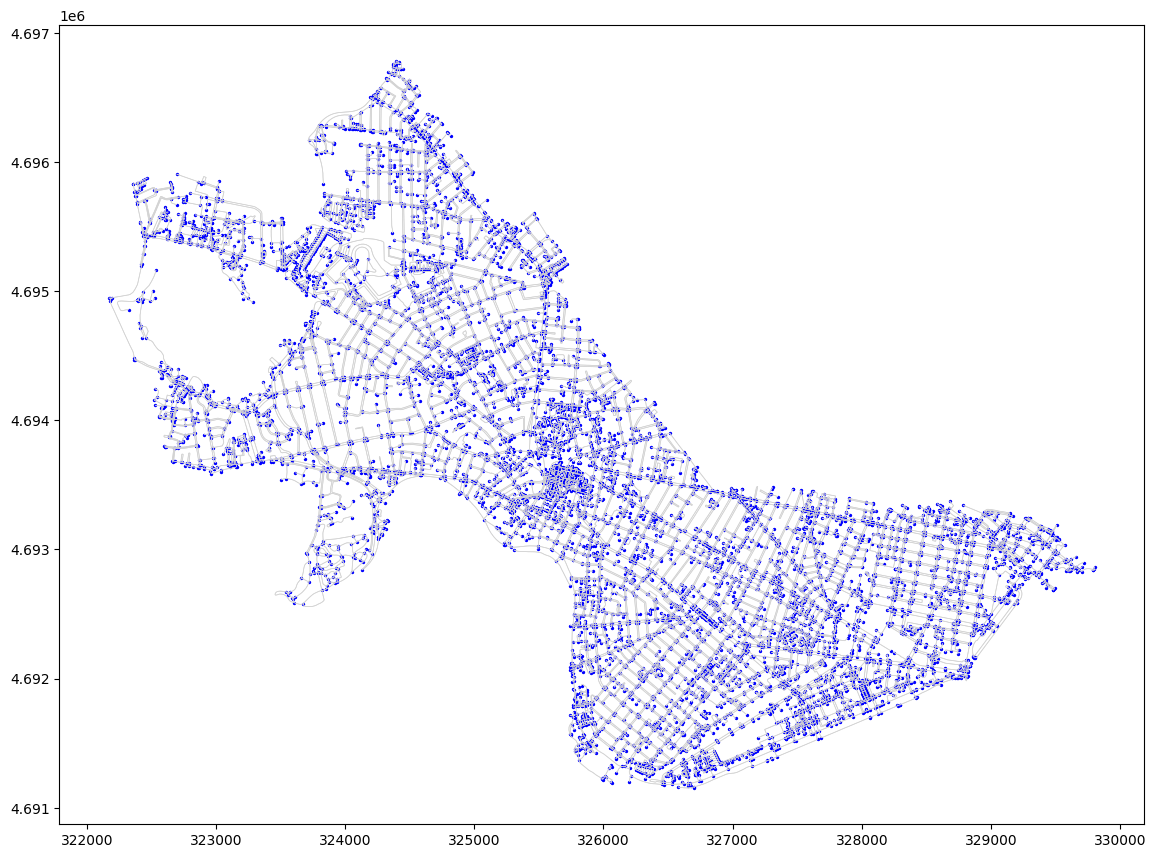

In [38]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 12))

# Draw pedestrian network
edges_projected.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5
)

# Draw pedestrian network nodes
nodes_projected.plot(
    ax=ax,
    color="blue",
    markersize=2
)

# Display location names
for idx, row in locations_gdf.iterrows():
    ax.annotate(
        text=row["place_name"],
        xy=(row.geometry.x, row.geometry.y),
        fontsize=9,
        color="red",
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_title("Cambridge Pedestrian Network and Key Locations")
ax.set_axis_off()

plt.show()

In [39]:
print("Network CRS:", edges_projected.crs)
print("Network bounds:", edges_projected.total_bounds)

print("Network covers:")
print(edges_projected.total_bounds)

Network CRS: EPSG:32619
Network bounds: [ 322170.95024829 4691153.84440806  329806.4601206  4696779.76159571]
Network covers:
[ 322170.95024829 4691153.84440806  329806.4601206  4696779.76159571]


In [40]:
import geopandas as gpd

locations_gdf = gpd.read_file(
    r"E:\Jupyter Notebook\Cambridge_geocoded.gpkg"
)

print("Geocoded CRS:", locations_gdf.crs)

locations_projected = locations_gdf.to_crs(
    edges_projected.crs
)

print(
    locations_projected[
        ["place_name", "geometry"]
    ]
)

Geocoded CRS: EPSG:4326
                                          place_name  \
0       Porter Square, Cambridge, Massachusetts, USA   
1        Inman Square, Cambridge, Massachusetts, USA   
2    Lechmere Station, Cambridge, Massachusetts, USA   
3     Alewife Station, Cambridge, Massachusetts, USA   
4  Harvard University, Cambridge, Massachusetts, USA   
5                 MIT, Cambridge, Massachusetts, USA   
6      Kendall Square, Cambridge, Massachusetts, USA   
7      Central Square, Cambridge, Massachusetts, USA   
8  Cambridge Public Library, Cambridge, Massachus...   

                         geometry  
0  POINT (325564.522 4695059.323)  
1  POINT (327048.478 4693400.819)  
2  POINT (329057.826 4693088.073)  
3  POINT (323764.449 4695966.361)  
4  POINT (325249.588 4692566.943)  
5  POINT (327336.056 4691682.902)  
6   POINT (328090.552 4692148.56)  
7  POINT (326748.744 4692503.601)  
8   POINT (326239.43 4693458.288)  


In [41]:
xmin, ymin, xmax, ymax = edges_projected.total_bounds

locations_projected["inside_network_bounds"] = (
    locations_projected.geometry.x.between(xmin, xmax)
    &
    locations_projected.geometry.y.between(ymin, ymax)
)

print(
    locations_projected[
        ["place_name", "inside_network_bounds"]
    ]
)

                                          place_name  inside_network_bounds
0       Porter Square, Cambridge, Massachusetts, USA                   True
1        Inman Square, Cambridge, Massachusetts, USA                   True
2    Lechmere Station, Cambridge, Massachusetts, USA                   True
3     Alewife Station, Cambridge, Massachusetts, USA                   True
4  Harvard University, Cambridge, Massachusetts, USA                   True
5                 MIT, Cambridge, Massachusetts, USA                   True
6      Kendall Square, Cambridge, Massachusetts, USA                   True
7      Central Square, Cambridge, Massachusetts, USA                   True
8  Cambridge Public Library, Cambridge, Massachus...                   True


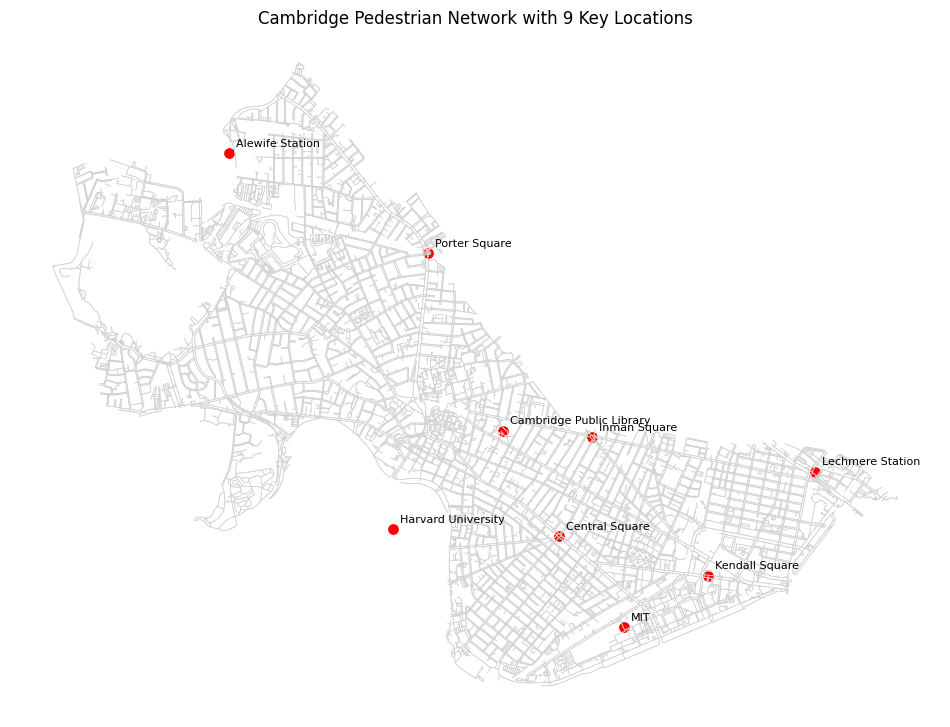

In [42]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

# Pedestrian network
edges_projected.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5
)

# Nine locations
locations_projected.plot(
    ax=ax,
    color="red",
    markersize=45,
    marker="o"
)

# Add location names
for idx, row in locations_projected.iterrows():
    ax.annotate(
        row["place_name"].split(",")[0],
        (row.geometry.x, row.geometry.y),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_title("Cambridge Pedestrian Network with 9 Key Locations")
ax.set_axis_off()

plt.show()

In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
locations = {
    "Porter Square": (42.3884, -71.1191),
    "Inman Square": (42.3743, -71.1003),
    "Lechmere Station": (42.3702, -71.0765),
    "Alewife Station": (42.3954, -71.1425),
    "MIT": (42.3592, -71.0935),
    "Kendall Square": (42.3621, -71.0862),
    "Central Square": (42.3654, -71.1037),
    "Cambridge Public Library": (42.3736, -71.1112)
}

In [3]:
data = []

for name, (lat, lon) in locations.items():
    data.append({
        "location": name,
        "latitude": lat,
        "longitude": lon
    })

df = pd.DataFrame(data)

points = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(
        df.longitude,
        df.latitude
    ),
    crs="EPSG:4326"
)

print(points)

                   location  latitude  longitude                  geometry
0             Porter Square   42.3884   -71.1191  POINT (-71.1191 42.3884)
1              Inman Square   42.3743   -71.1003  POINT (-71.1003 42.3743)
2          Lechmere Station   42.3702   -71.0765  POINT (-71.0765 42.3702)
3           Alewife Station   42.3954   -71.1425  POINT (-71.1425 42.3954)
4                       MIT   42.3592   -71.0935  POINT (-71.0935 42.3592)
5            Kendall Square   42.3621   -71.0862  POINT (-71.0862 42.3621)
6            Central Square   42.3654   -71.1037  POINT (-71.1037 42.3654)
7  Cambridge Public Library   42.3736   -71.1112  POINT (-71.1112 42.3736)


In [4]:
points.to_file(
    "cambridge_8_points.gpkg",
    layer="locations",
    driver="GPKG"
)

print("Eight points saved successfully!")

Eight points saved successfully!
